In [160]:
#forces us to reload the libraries each time we do a function call,
#so I can update things in real time
%load_ext autoreload
%autoreload 2
#import path libraries
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
EXPERIMENT_DIR = ROOT / "systematic_testing" / "correction_comparison"
FIGURES_DIR = EXPERIMENT_DIR / "figures"
RESULTS_DIR = EXPERIMENT_DIR / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
from utils import psf
from utils import plotting
from utils import zernike
from optimization import reconstruction
from tqdm.auto import tqdm
from systematic_testing import correction


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [161]:
plt.style.use("bmh")
plt.rcParams["figure.figsize"] = [548 / 72, 390 / 72]
plt.rcParams["font.size"] = 12
plt.rcParams['text.usetex'] = True
plt.rcParams["figure.dpi"] = 300

In [169]:
N_order = 3                # 3 for 3P, 2 for 2P
lambd = 1.3e-3             # Wavelength [mm]
n = 1.333                  # Refractive index
k = 2*n*np.pi/lambd        # Wavenumber
num_apt = 1.05             # Numerical aperture
f = 7.2                    # Focal length of objective (Olympus) [mm]
grid_size = 128            # BFP resolution
L_bfp = 15.12              # BFP diameter [mm]
mag = 4                    # Magnification rate from input to objective
w_0 = 3.5                  # mm
num_apt = 1.05
L_ffp = 0.0065             # FFP size [mm]
grid_ffp = 32
grid_bfp = 32

Compare repeated stack fitting with a modal Booth $2N+1$ baseline. The sample and unknown wavefront remain fixed within each trial; the SLM phase accumulates, and each acquisition observes the remaining aberration plus its temporary probe.

Exposure is calibrated once from the noiseless initial zero-bias image at z=0, then shared by both methods. `INITIAL_REFERENCE_SNR` sets this reference exposure; subsequent SNR changes naturally with brightness. Every measured z-plane counts as one image. RMS is a simulation diagnostic and does not guide either correction algorithm. The SLM is ideal, with no drift, bleaching, or calibration error.

The Booth baseline uses mean fluorescence intensity and bounded three-point quadratic fits, with one baseline shared across all modes before applying their updates together. This is the basic modal benchmark, without orthogonalization for the image metric. [Method reference](https://doi.org/10.1364/OE.20.002598).


In [170]:
microscope = psf.Microscope(N_order = N_order,
                            lambd = lambd,
                            n = n,
                            num_apt = num_apt,
                            f = f,
                            mag = mag,
                            w_0 = w_0,
                            L_bfp = L_bfp,
                            grid_bfp = grid_bfp)

grid = psf.Centered_Square_Grid(L_ffp = L_ffp,
                                grid_ffp = grid_ffp,
                                z_level = 0)

xs, ys = grid.get_xy()


modes = [[-2,2],
         [2,2],
         [-3,3],
         [-1,3],
         [1,3],
         [3,3],
         [-4,4],
         [-2,4],
         [0,4],
         [2,4],
         [4,4],
         [-5,5],
         [-3, 5],
         [-1, 5],
         [1, 5],
         [3, 5],
         [5,5]]


In [176]:
NUM_TRIALS = 1
ABERRATION_RMS = 0.10
ABERRATION_SEED = 0
NOISE_SEED = 1
INITIAL_REFERENCE_SNR = 10.0  # SNR of the unaberrated reference at focus z=0.
RHO = 1e46
IMAGE_BUDGET = 200
OPTICAL_MODE = "vector"
CORRECTION_MODES = [mode.copy() for mode in modes]
CORRECTION_GAIN = 1.0
MAX_MODAL_UPDATE = 0.10  # Maximum SLM increment per mode per update, in waves.

NUM_RECONSTRUCTION_PLANES = 21  # Independent of the 41 simulation planes; odd counts include z=0.
NUM_STACK_Z_PLANES = 8
STACK_FOCAL_POSITIONS = np.linspace(-0.002, 0.002, NUM_STACK_Z_PLANES)
STACK_DIVERSITY_MODES = [[0, 4], [-2, 2], [2, 2]]
STACK_DIVERSITY_STRATEGY = "joint"  # Fit spherical and both astigmatisms together every loop.
STACK_DIVERSITY_STRENGTHS = np.array([-0.10, 0.0, 0.10])
STACK_DIVERSITY_DECAY = 0.8  # Multiply bias amplitudes after each correction; 1.0 disables decay.
STACK_MIN_DIVERSITY_STRENGTH = 0.02  # Floor for nonzero bias magnitudes, in waves.
OPTIMIZER_OPTIONS = dict(method="newton", max_iterations=20, verbose=False,
                         num_random_starts=100, random_start_rms_range=(0.005, 0.50),
                         random_start_seed=0)

BOOTH_FOCAL_POSITIONS = np.array([0.0])
BOOTH_BIAS = 0.10  # Probe coefficient in waves; adjust independently of the stack diversities.
BOOTH_METRIC = correction.mean_brightness

z_sample_levels = np.linspace(-0.002, 0.002, 41)
if (not isinstance(NUM_RECONSTRUCTION_PLANES, (int, np.integer))
        or isinstance(NUM_RECONSTRUCTION_PLANES, (bool, np.bool_))
        or NUM_RECONSTRUCTION_PLANES < 2):
    raise ValueError("NUM_RECONSTRUCTION_PLANES must be an integer >= 2.")
z_reconstruction_levels = np.linspace(
    z_sample_levels[0], z_sample_levels[-1], NUM_RECONSTRUCTION_PLANES,
)

mask_3D = psf.bead_img_3D(grid = grid,
                          z_levels = z_sample_levels,
                          xs = [0],
                          ys = [0],
                          zs = [0],
                          bead_sizes = [0.001])

stack_images_per_update = (len(STACK_FOCAL_POSITIONS) * len(STACK_DIVERSITY_MODES)
                           * len(STACK_DIVERSITY_STRENGTHS))
booth_images_per_update = len(BOOTH_FOCAL_POSITIONS) * (2 * len(CORRECTION_MODES) + 1)


### Initial trial preview

Run these cells after the configuration and before the correction comparison.
They show trial 1's unknown aberration and noisy acquisition stack with zero SLM
correction. Each focal position includes all three diversity modes and their known bias strengths.
The preview uses separate seeded RNGs, so it does not advance the main run's
random generators or consume its image budget. Rerun these cells after changing
the sample, optical parameters, seeds, or SNR. The reference exposure calculated
here is reused by the main run.


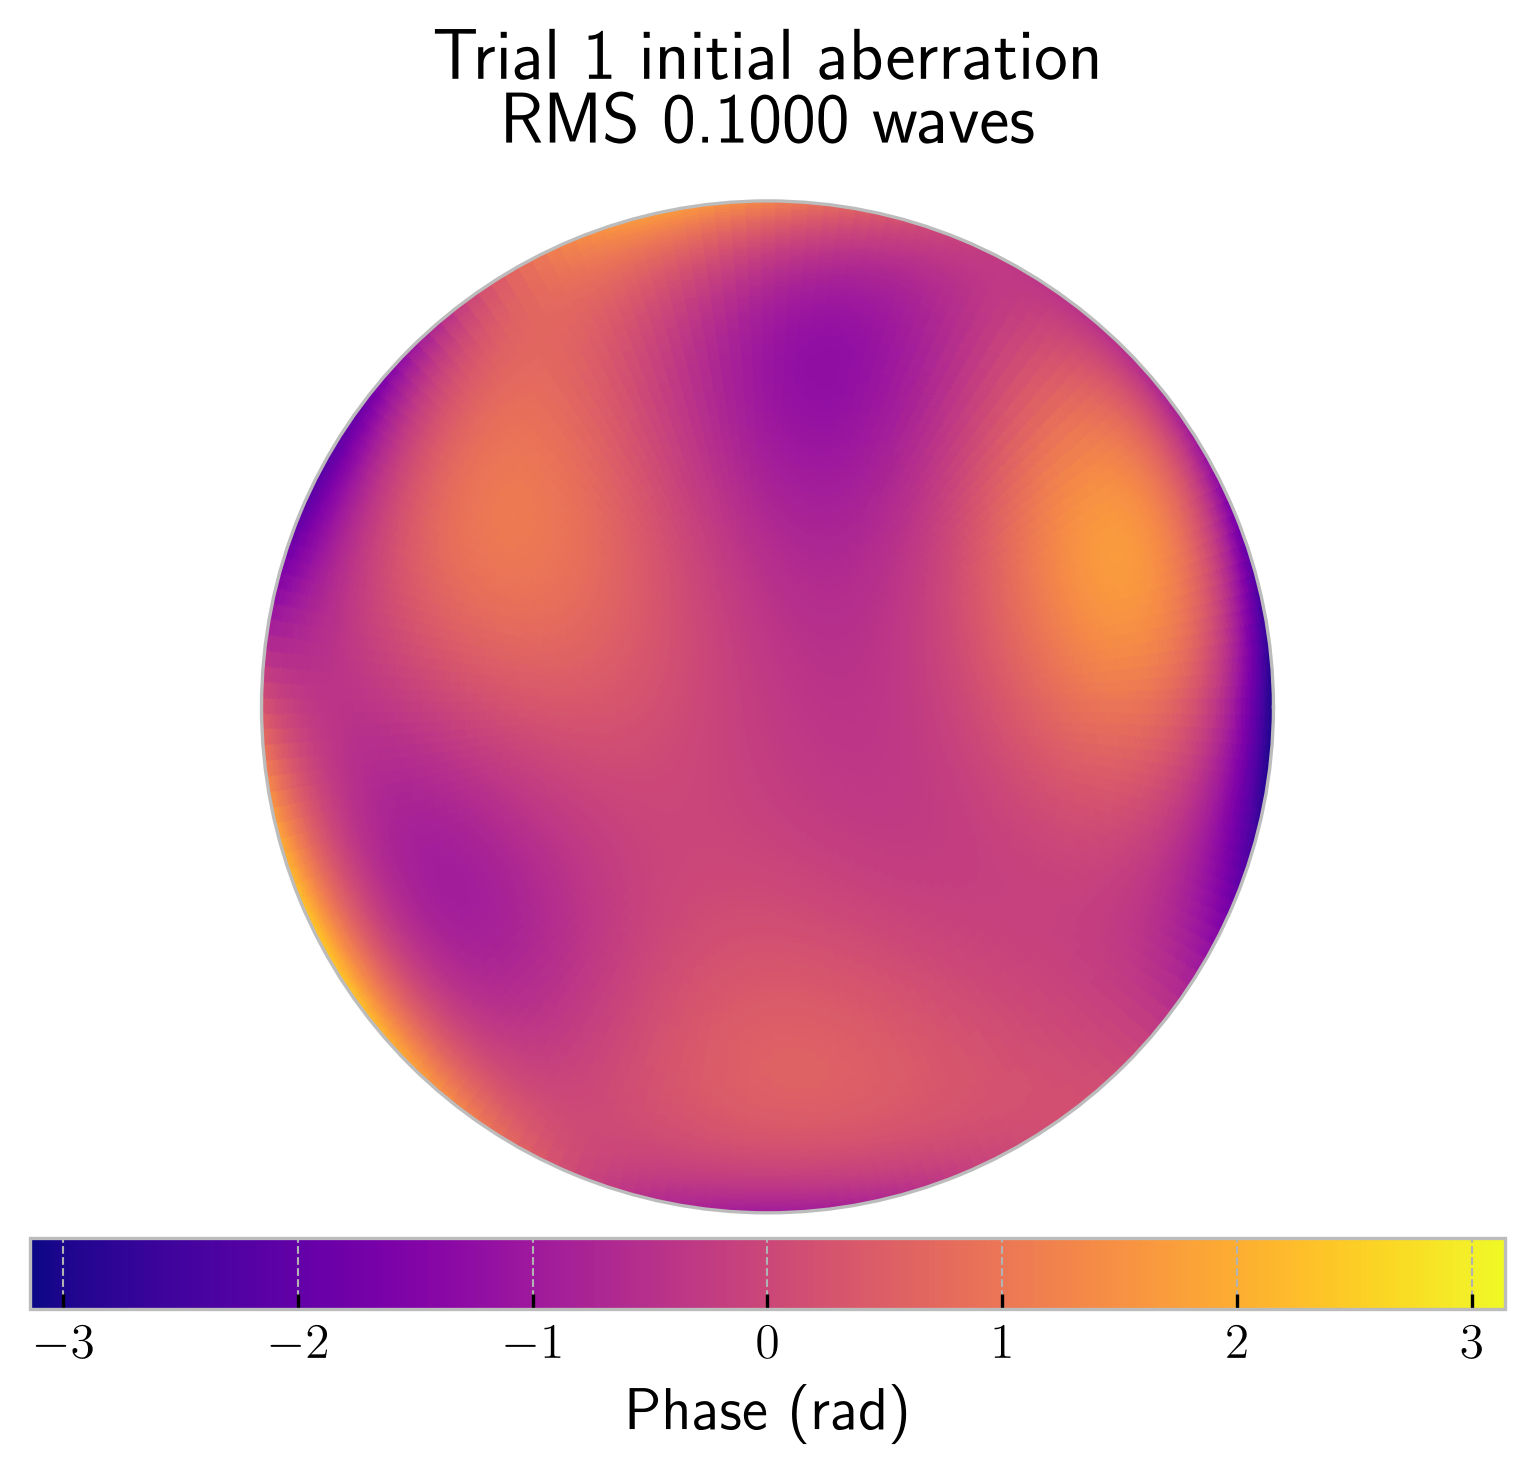

In [177]:
preview_pattern_rng = np.random.default_rng(np.random.SeedSequence([ABERRATION_SEED, 0]))
preview_truth = zernike.RMSAberration(
    modes=modes, raw_strengths=preview_pattern_rng.normal(0, 1, len(modes)),
    RMS_desired=ABERRATION_RMS, alpha=microscope.alpha,
)
preview_rms = zernike.zernike_RMS(preview_truth, microscope.alpha)
# Preserve the notebook's TeX font and give the phase colorbar its own row.
fig = plt.figure(figsize=(5, 4.8), layout="constrained")
phase_layout = fig.add_gridspec(2, 1, height_ratios=[1, 0.07])
ax = fig.add_subplot(phase_layout[0], projection="polar")
plotting.zernike_plot(preview_truth.construct_map(microscope.alpha), microscope.alpha,
                     res=201, ax=ax, show=False, colorbar=False)
ax.set_title(f"Trial 1 initial aberration\nRMS {preview_rms:.4f} waves", pad=14)
phase_cax = fig.add_subplot(phase_layout[1])
fig.colorbar(ax.collections[0], cax=phase_cax, orientation="horizontal", label="Phase (rad)")
plt.show()


In [178]:
# Calibrate fixed exposure once from the unaberrated reference at focus z=0.
print("Generating unaberrated reference and initial noisy stack...", flush=True)
_, _, _, reference_images = microscope.compute_image_3D(
    image=mask_3D, aberration=zernike.EmptyAberration(),
    focal_z_levels=np.array([0.0]), mode=OPTICAL_MODE,
)
fixed_exposure = correction.exposure_for_snr(reference_images, INITIAL_REFERENCE_SNR)
preview_focal_z = np.repeat(
    STACK_FOCAL_POSITIONS, len(STACK_DIVERSITY_MODES) * len(STACK_DIVERSITY_STRENGTHS))
preview_diversities = [
    zernike.Aberration([probe_mode], [strength])
    for _ in STACK_FOCAL_POSITIONS for probe_mode in STACK_DIVERSITY_MODES
    for strength in STACK_DIVERSITY_STRENGTHS
]
preview_simulator = correction.SimulatedSLM(
    microscope=microscope, sample=mask_3D, truth=preview_truth,
    correction_modes=CORRECTION_MODES, exposure=fixed_exposure,
    rng=np.random.default_rng(np.random.SeedSequence([NOISE_SEED, 0, 0])),
    optical_mode=OPTICAL_MODE,
)
preview_initial_stack = preview_simulator.acquire(preview_focal_z, preview_diversities)
print(f"Preview ready: {len(preview_initial_stack)} images; reference SNR {INITIAL_REFERENCE_SNR:g}; "
      f"fixed exposure {fixed_exposure:.5e}")


Generating unaberrated reference and initial noisy stack...
Preview ready: 72 images; reference SNR 10; fixed exposure 6.67261e-25


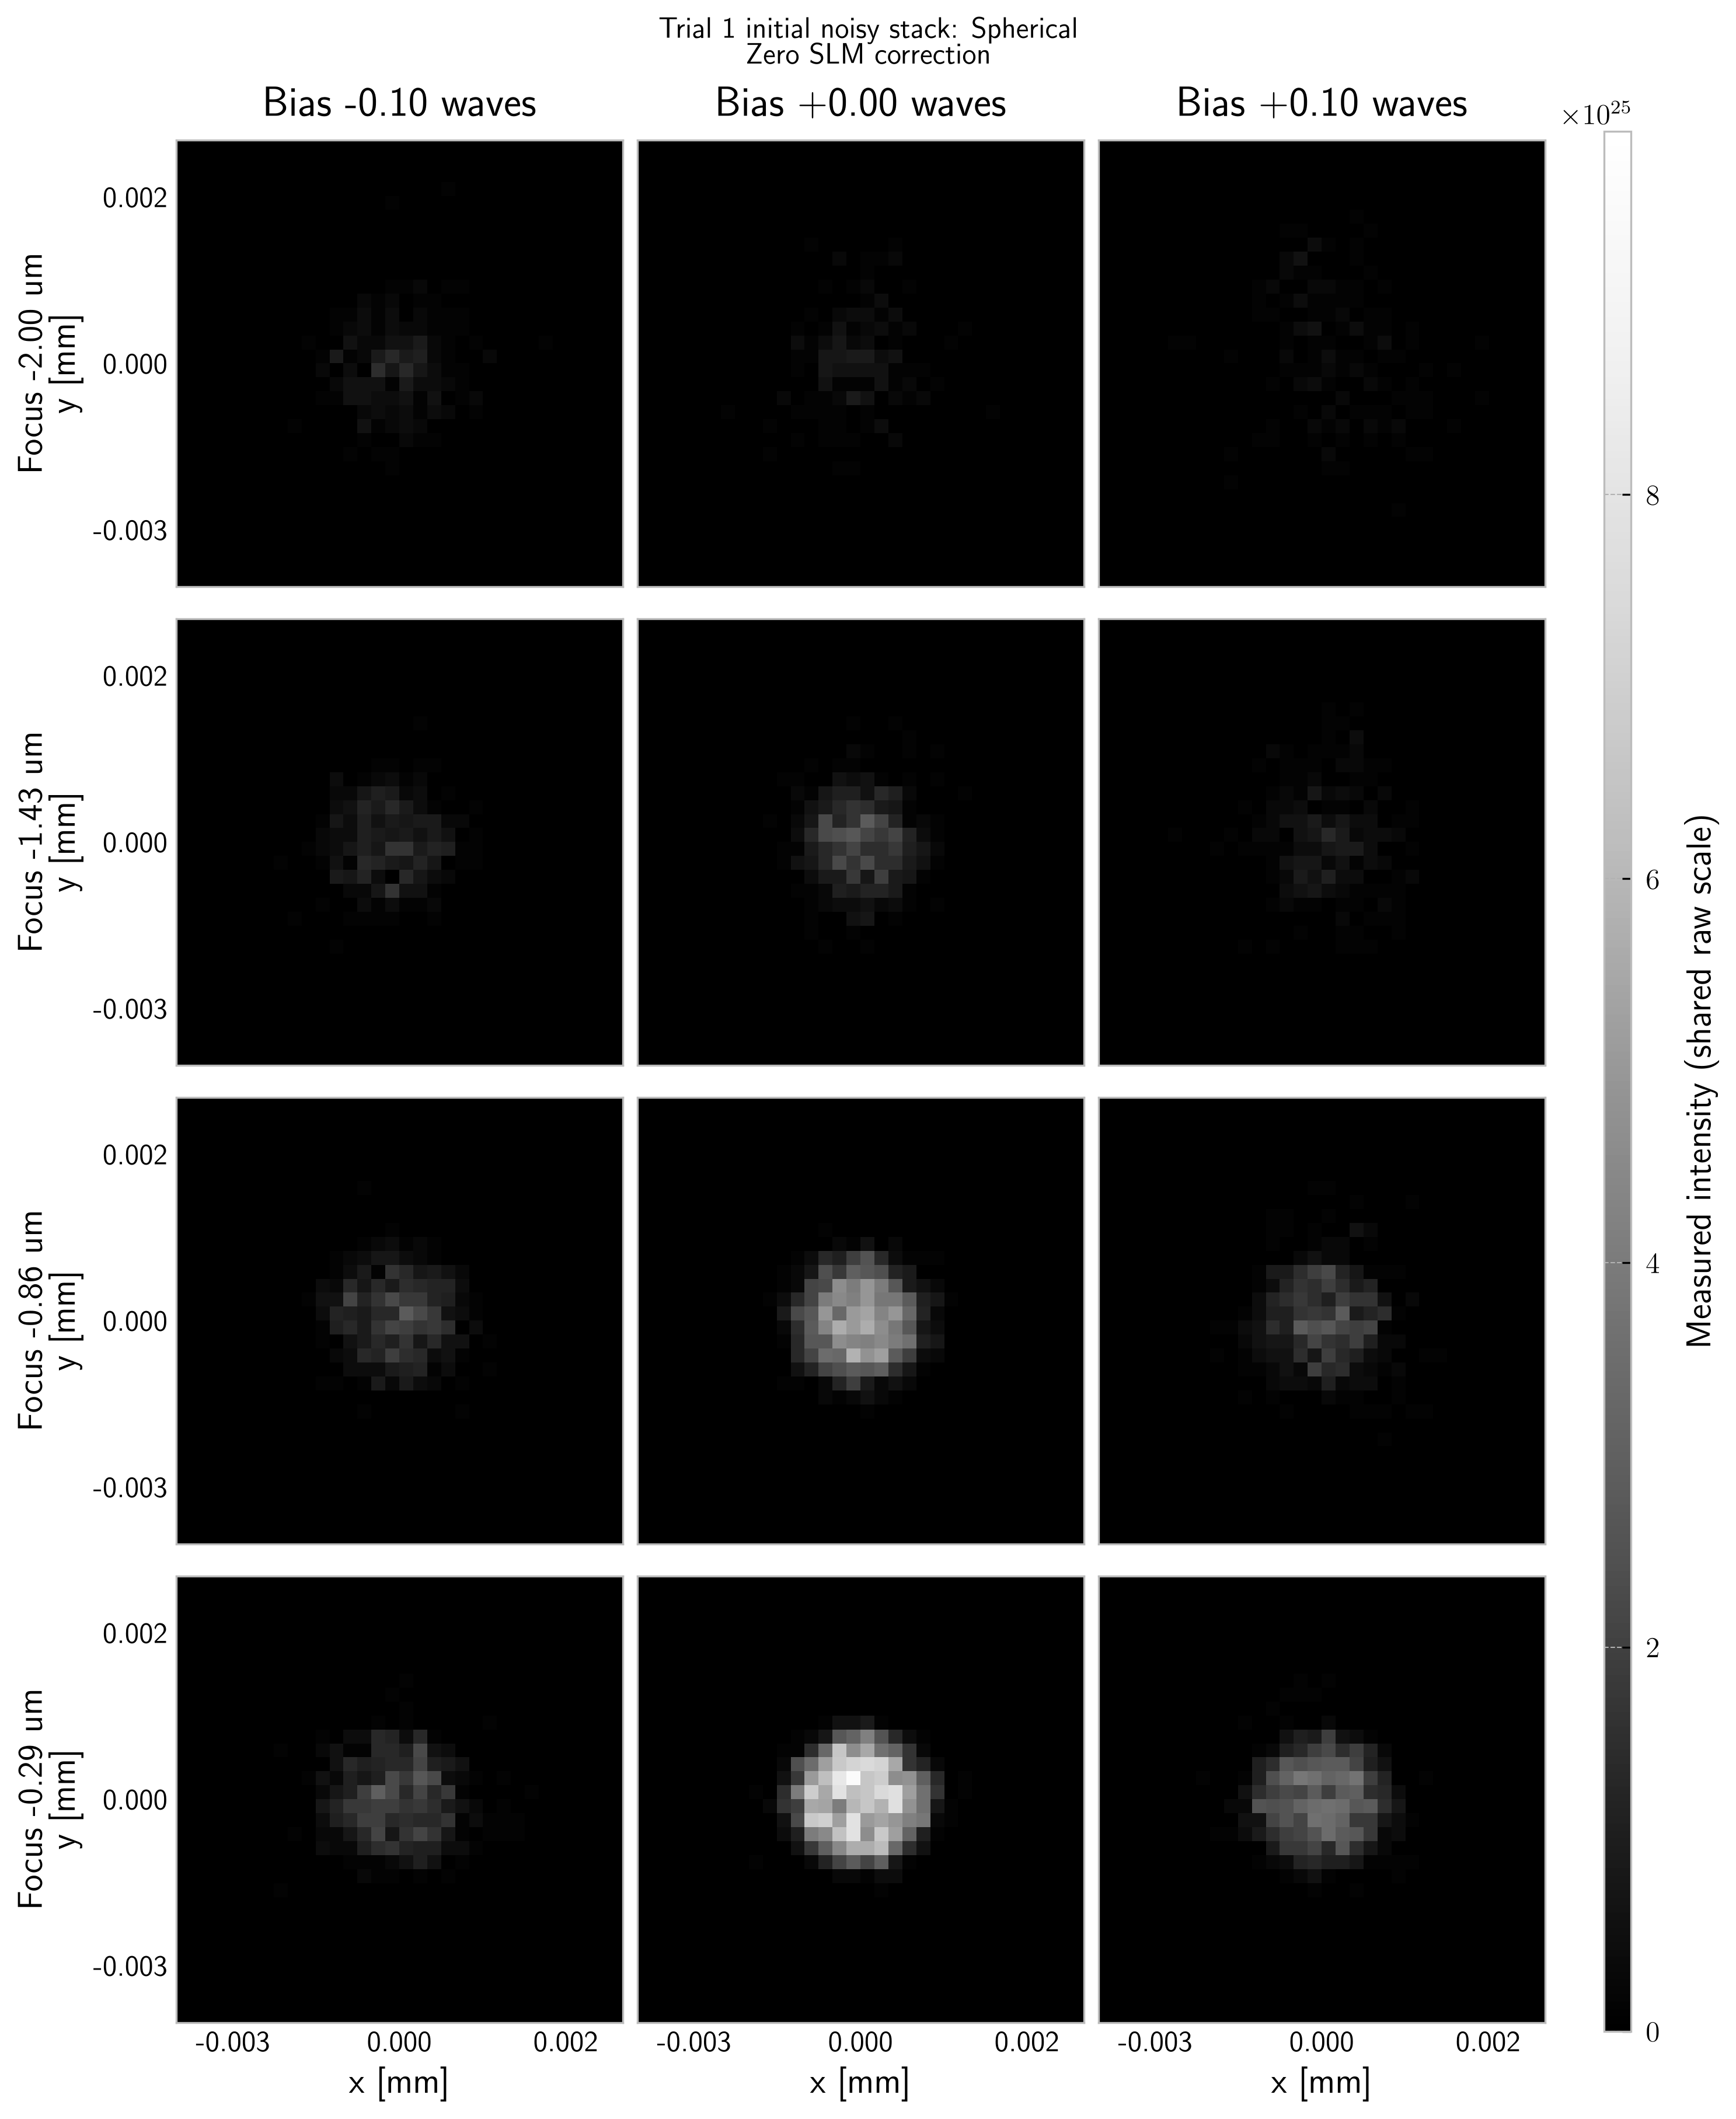

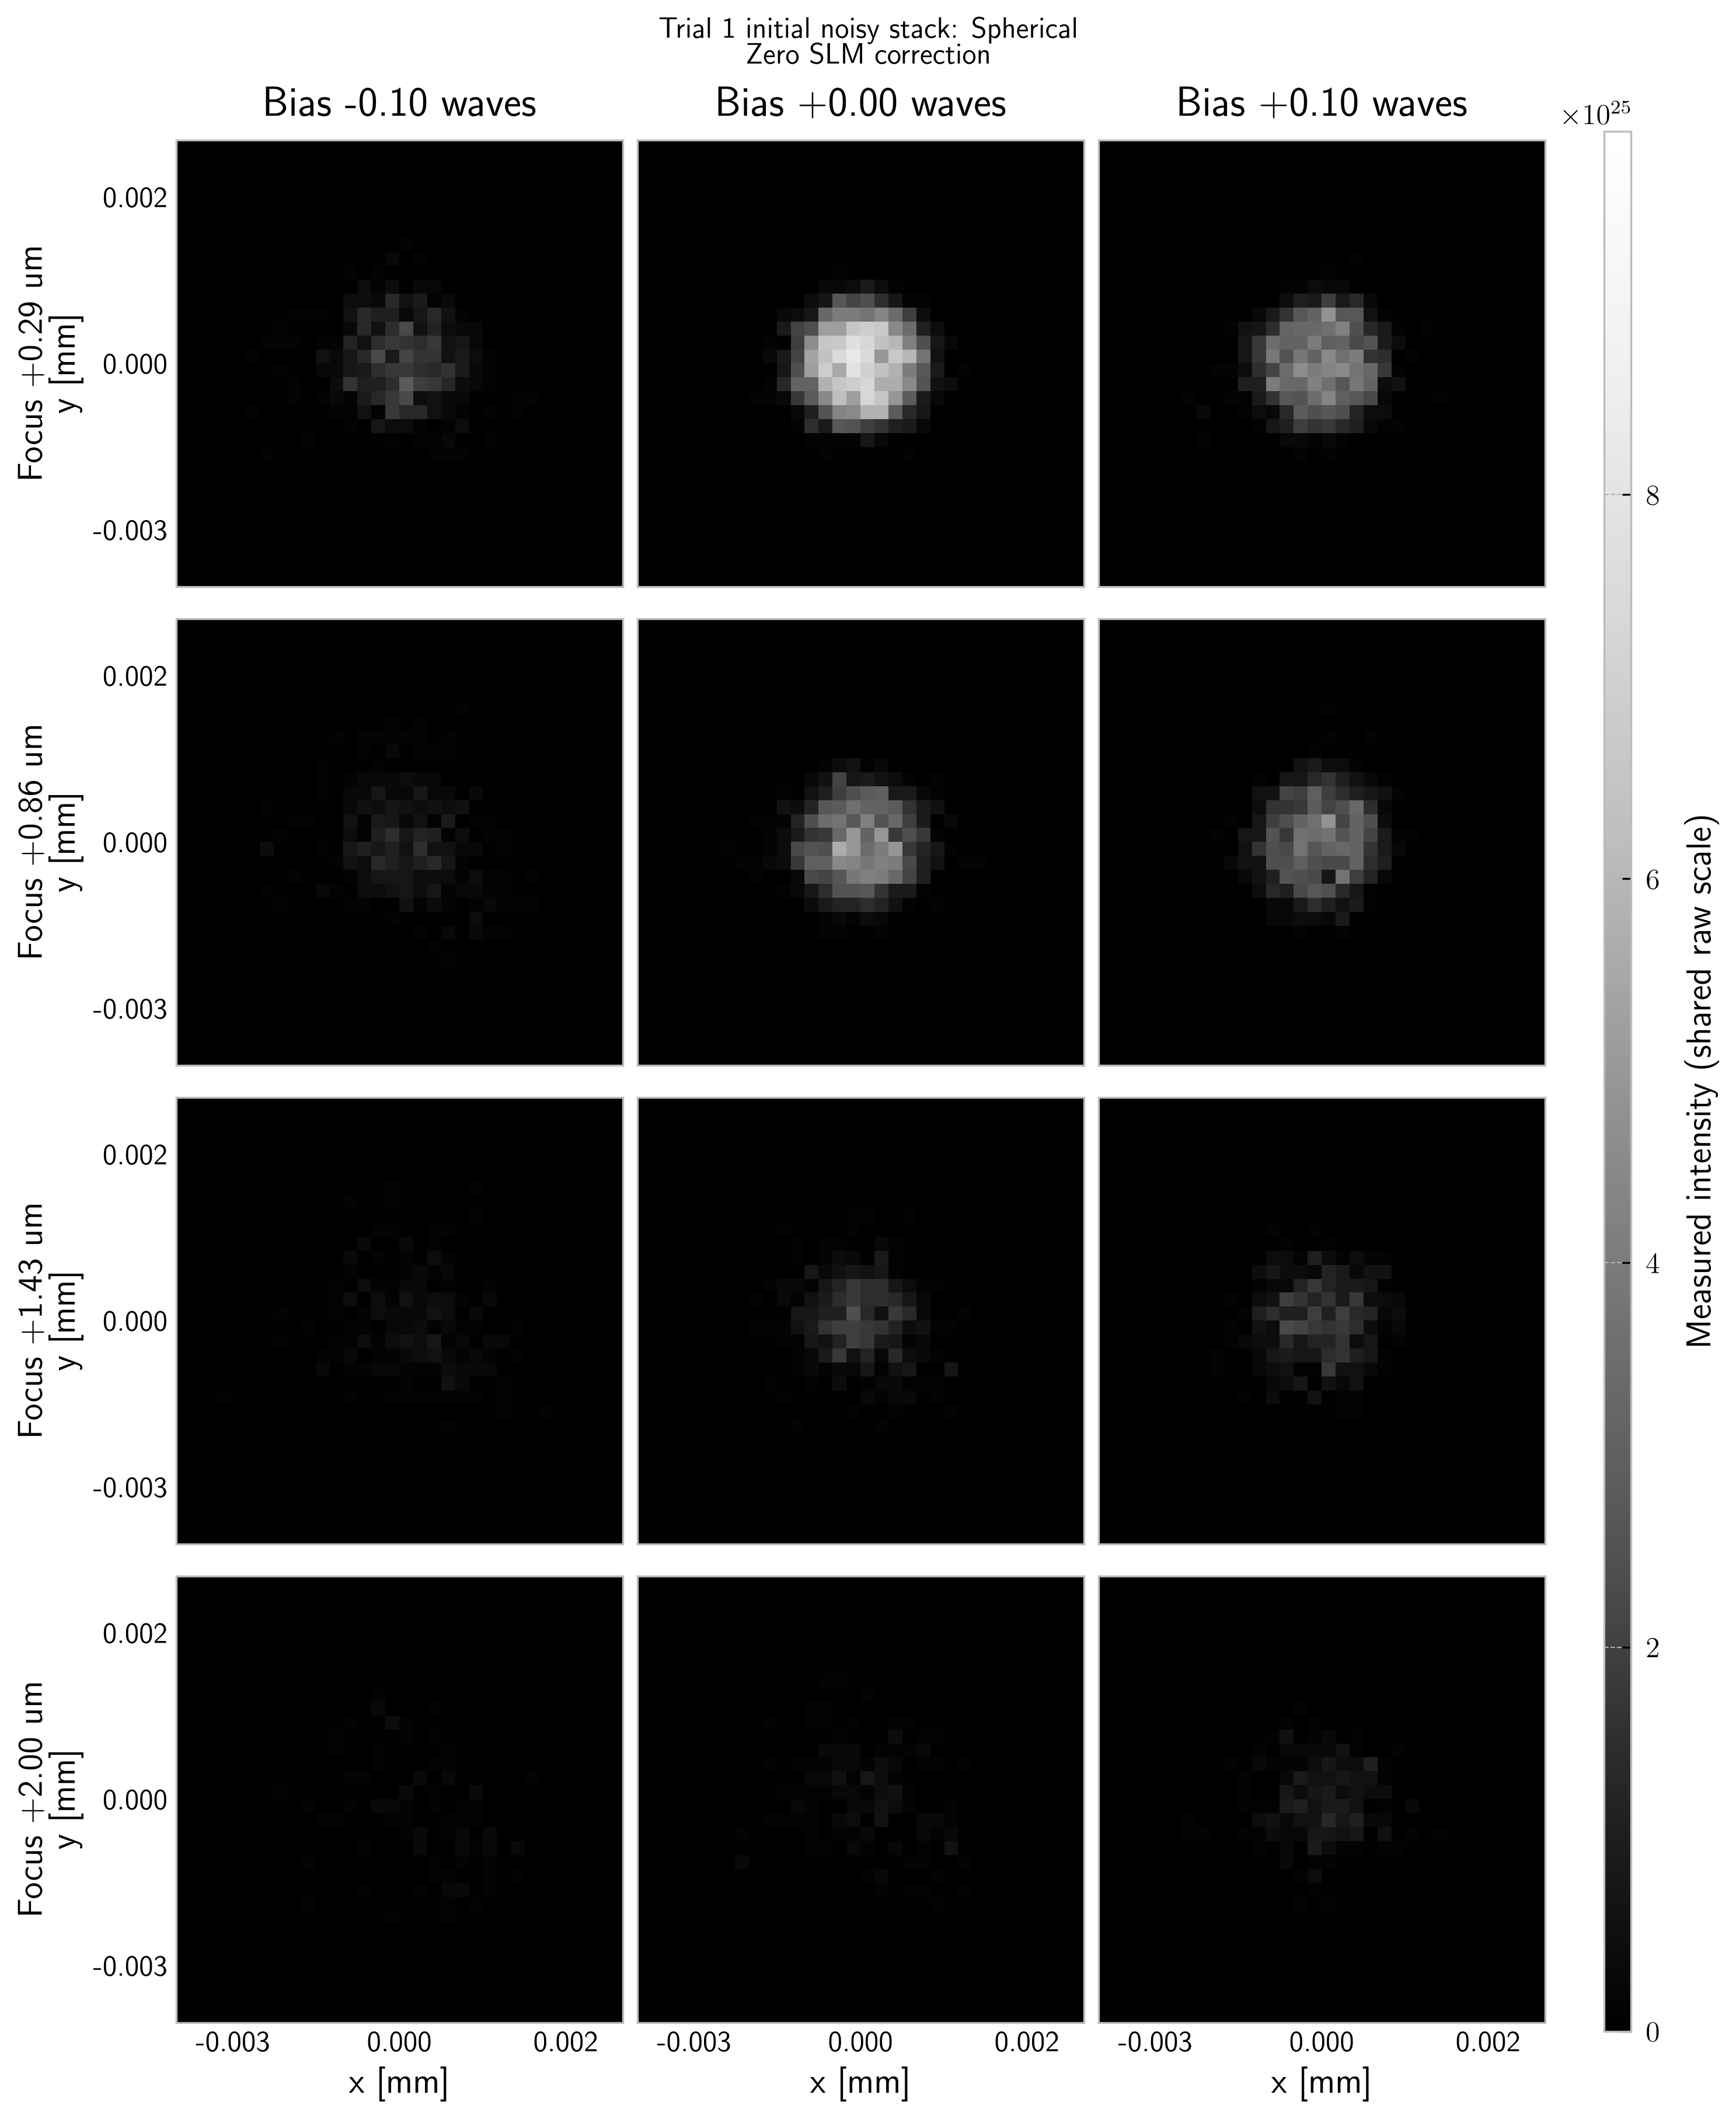

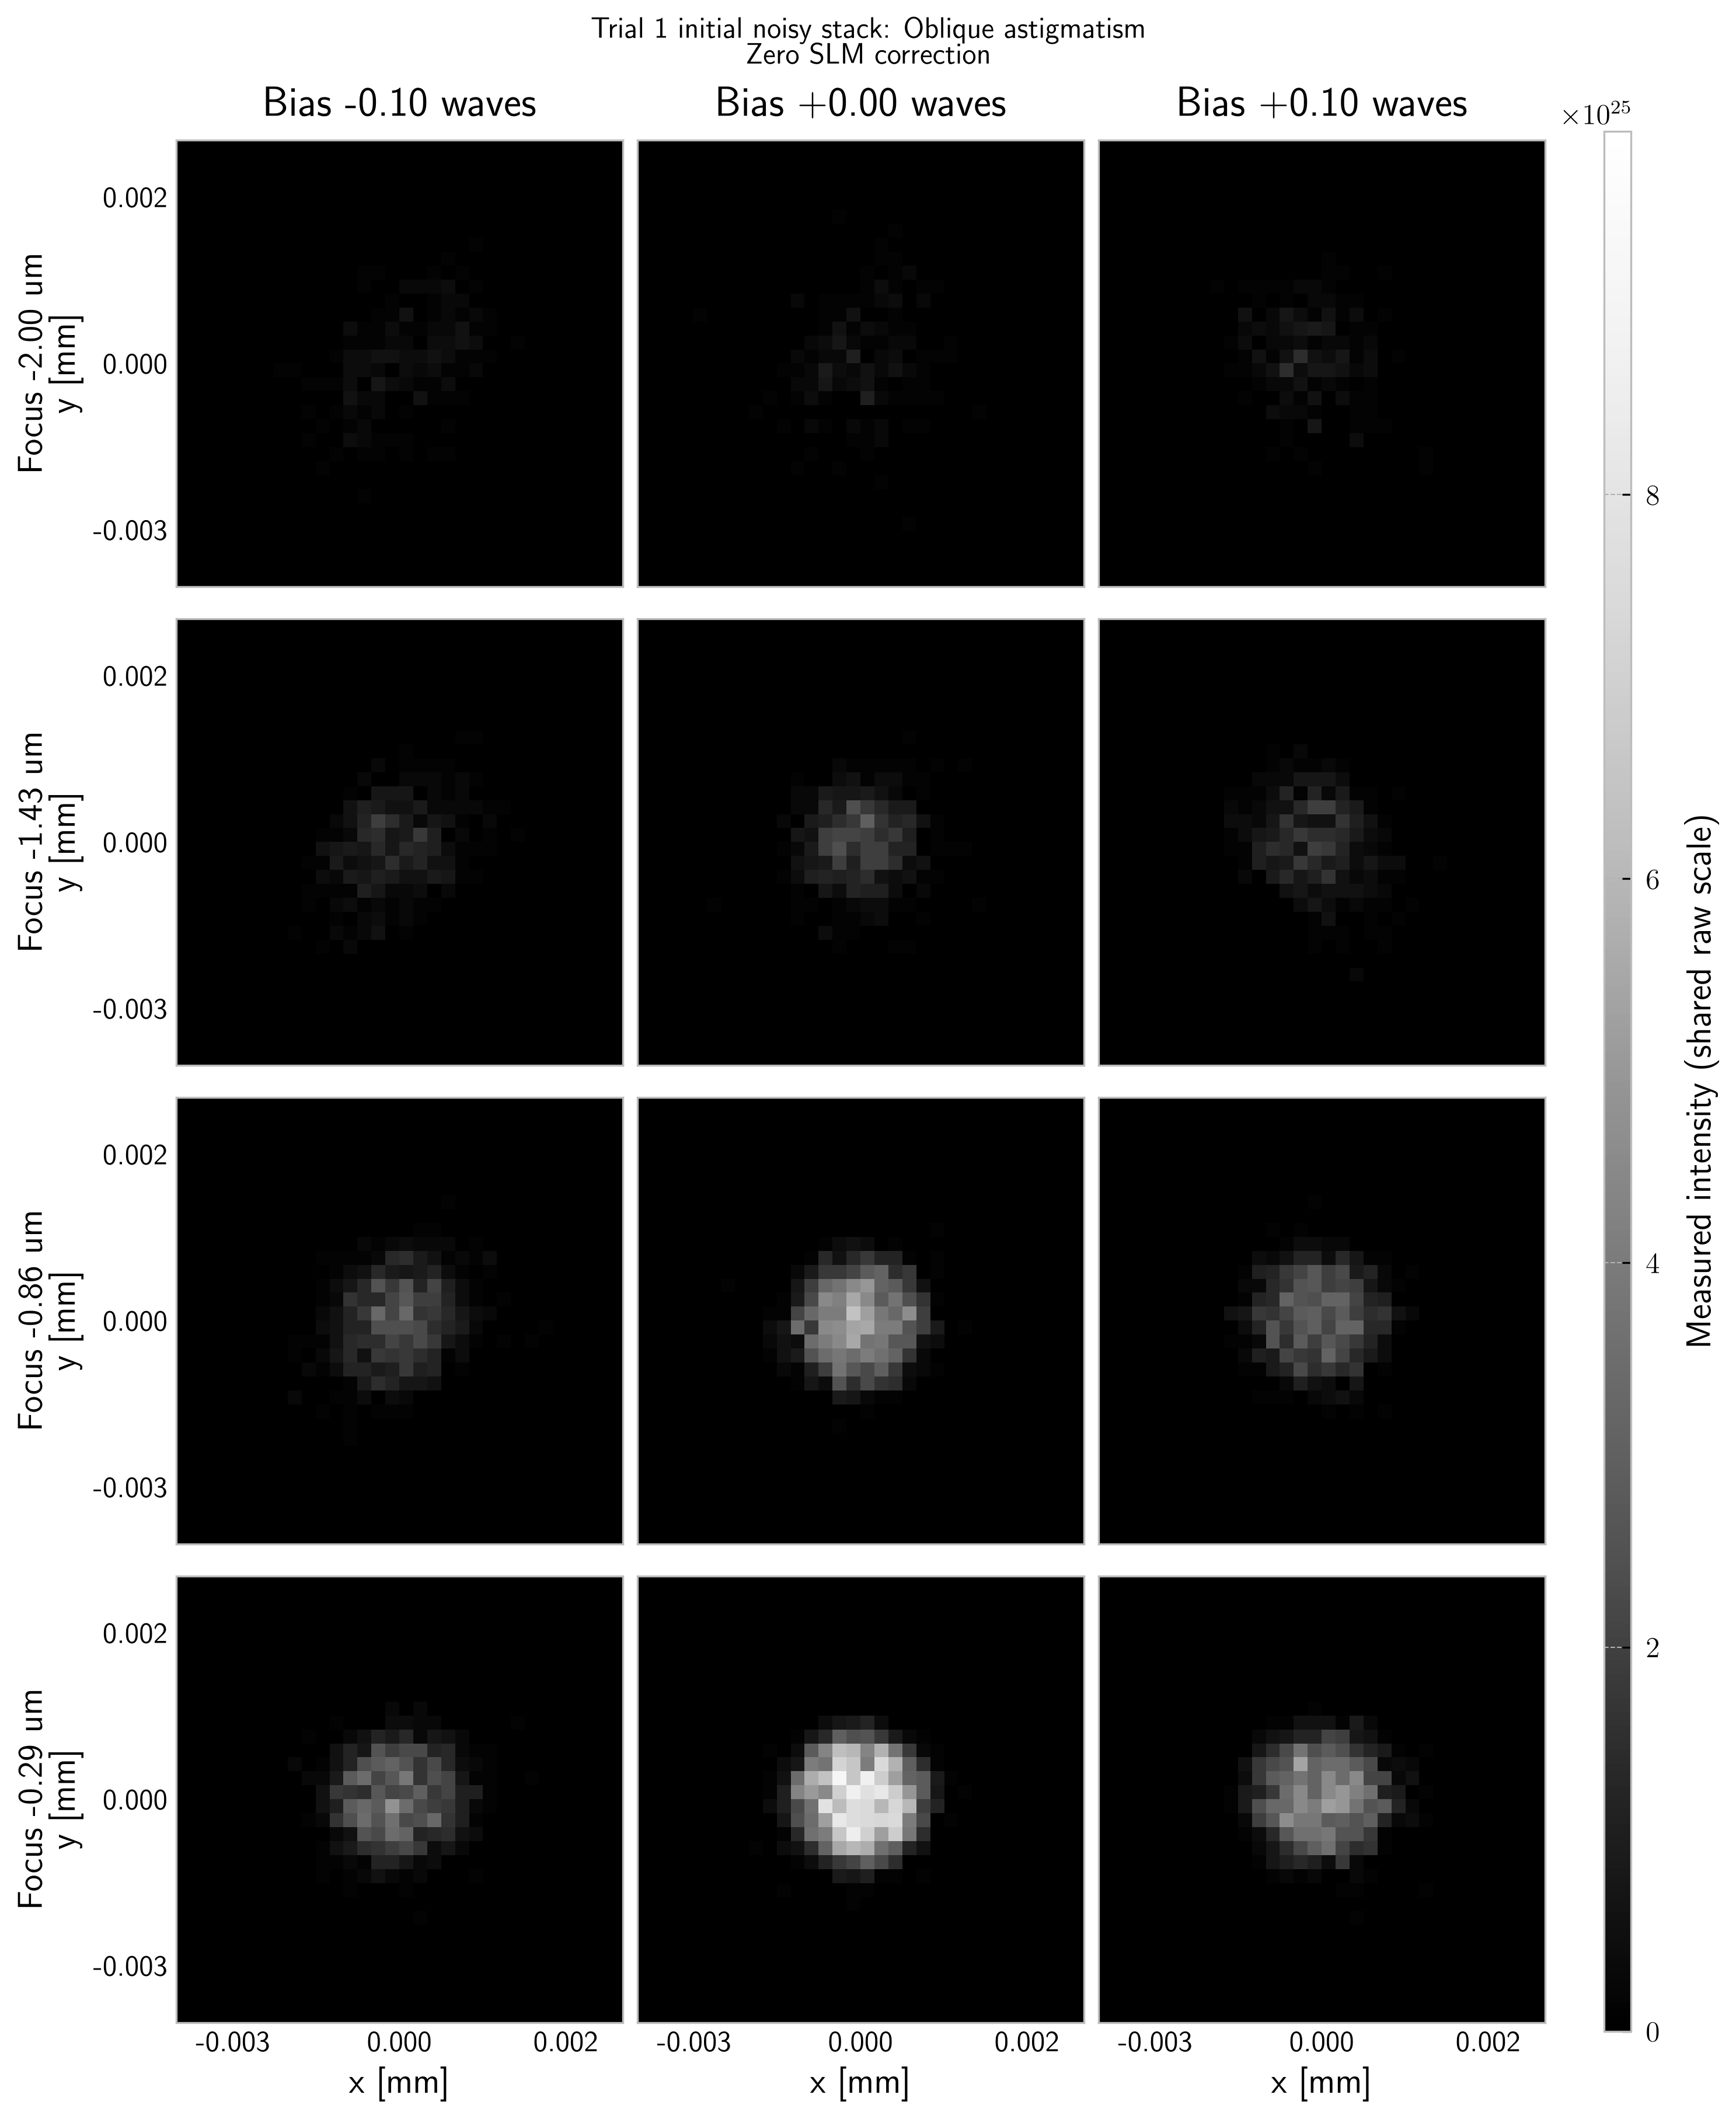

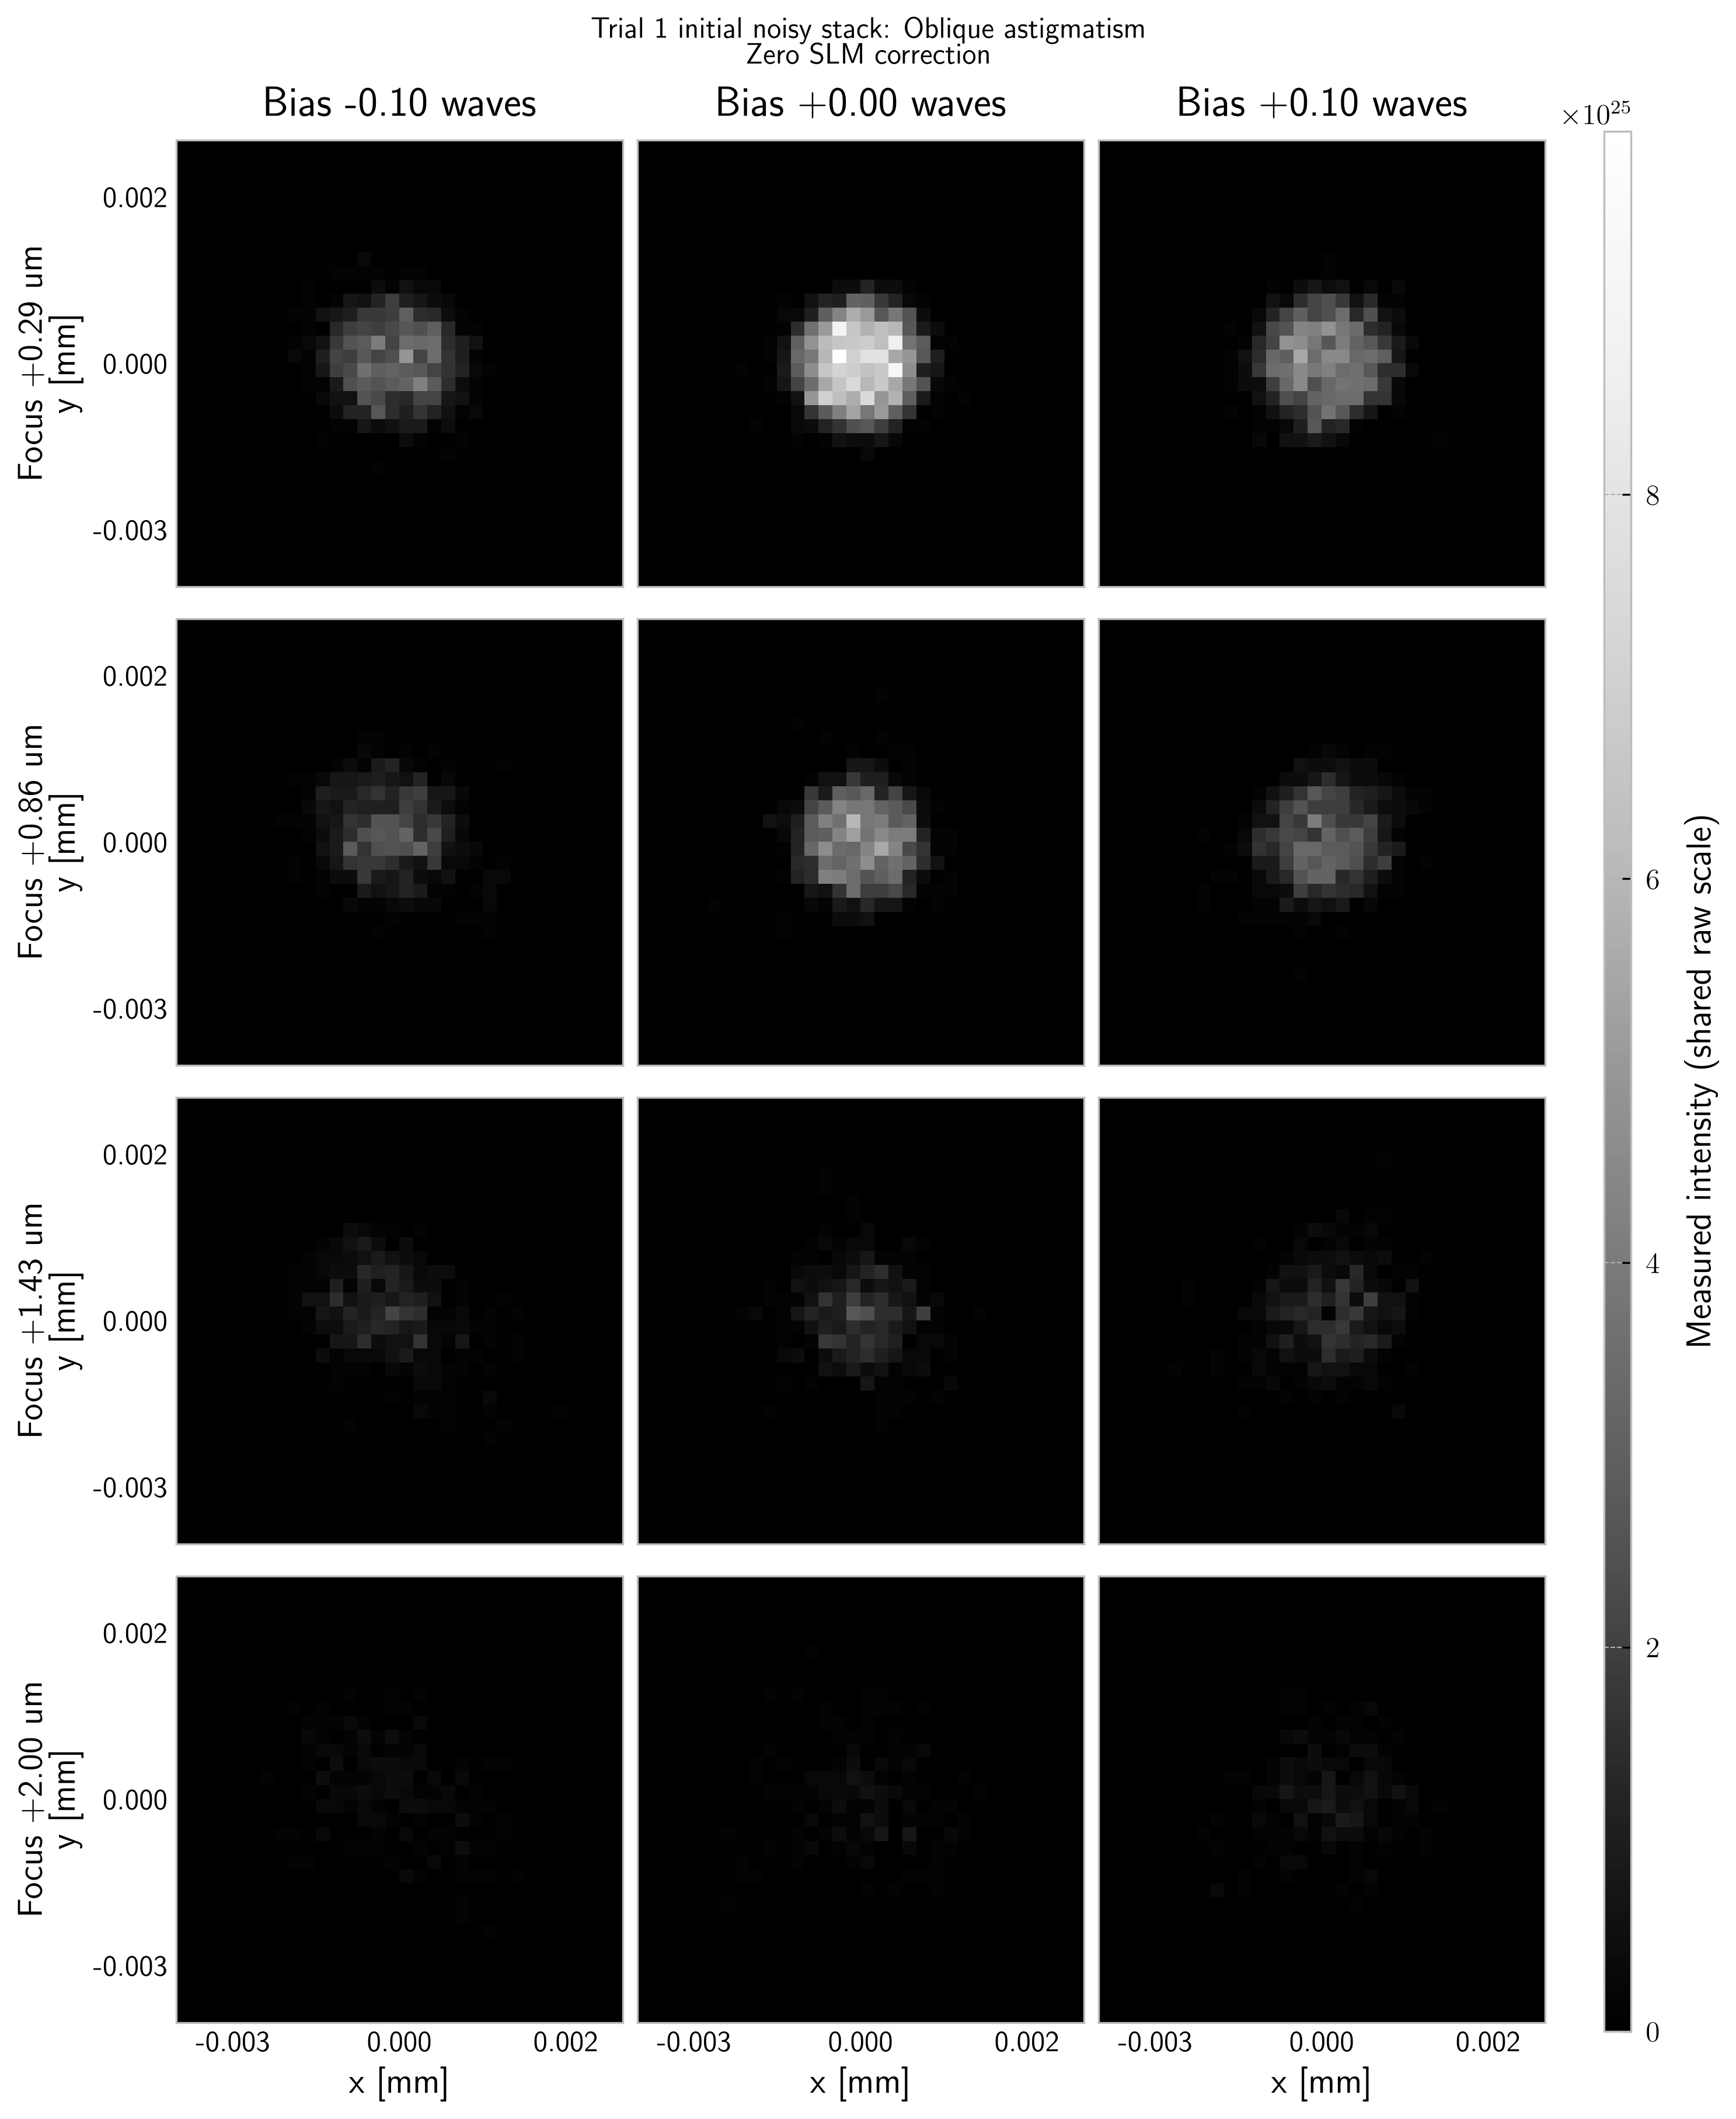

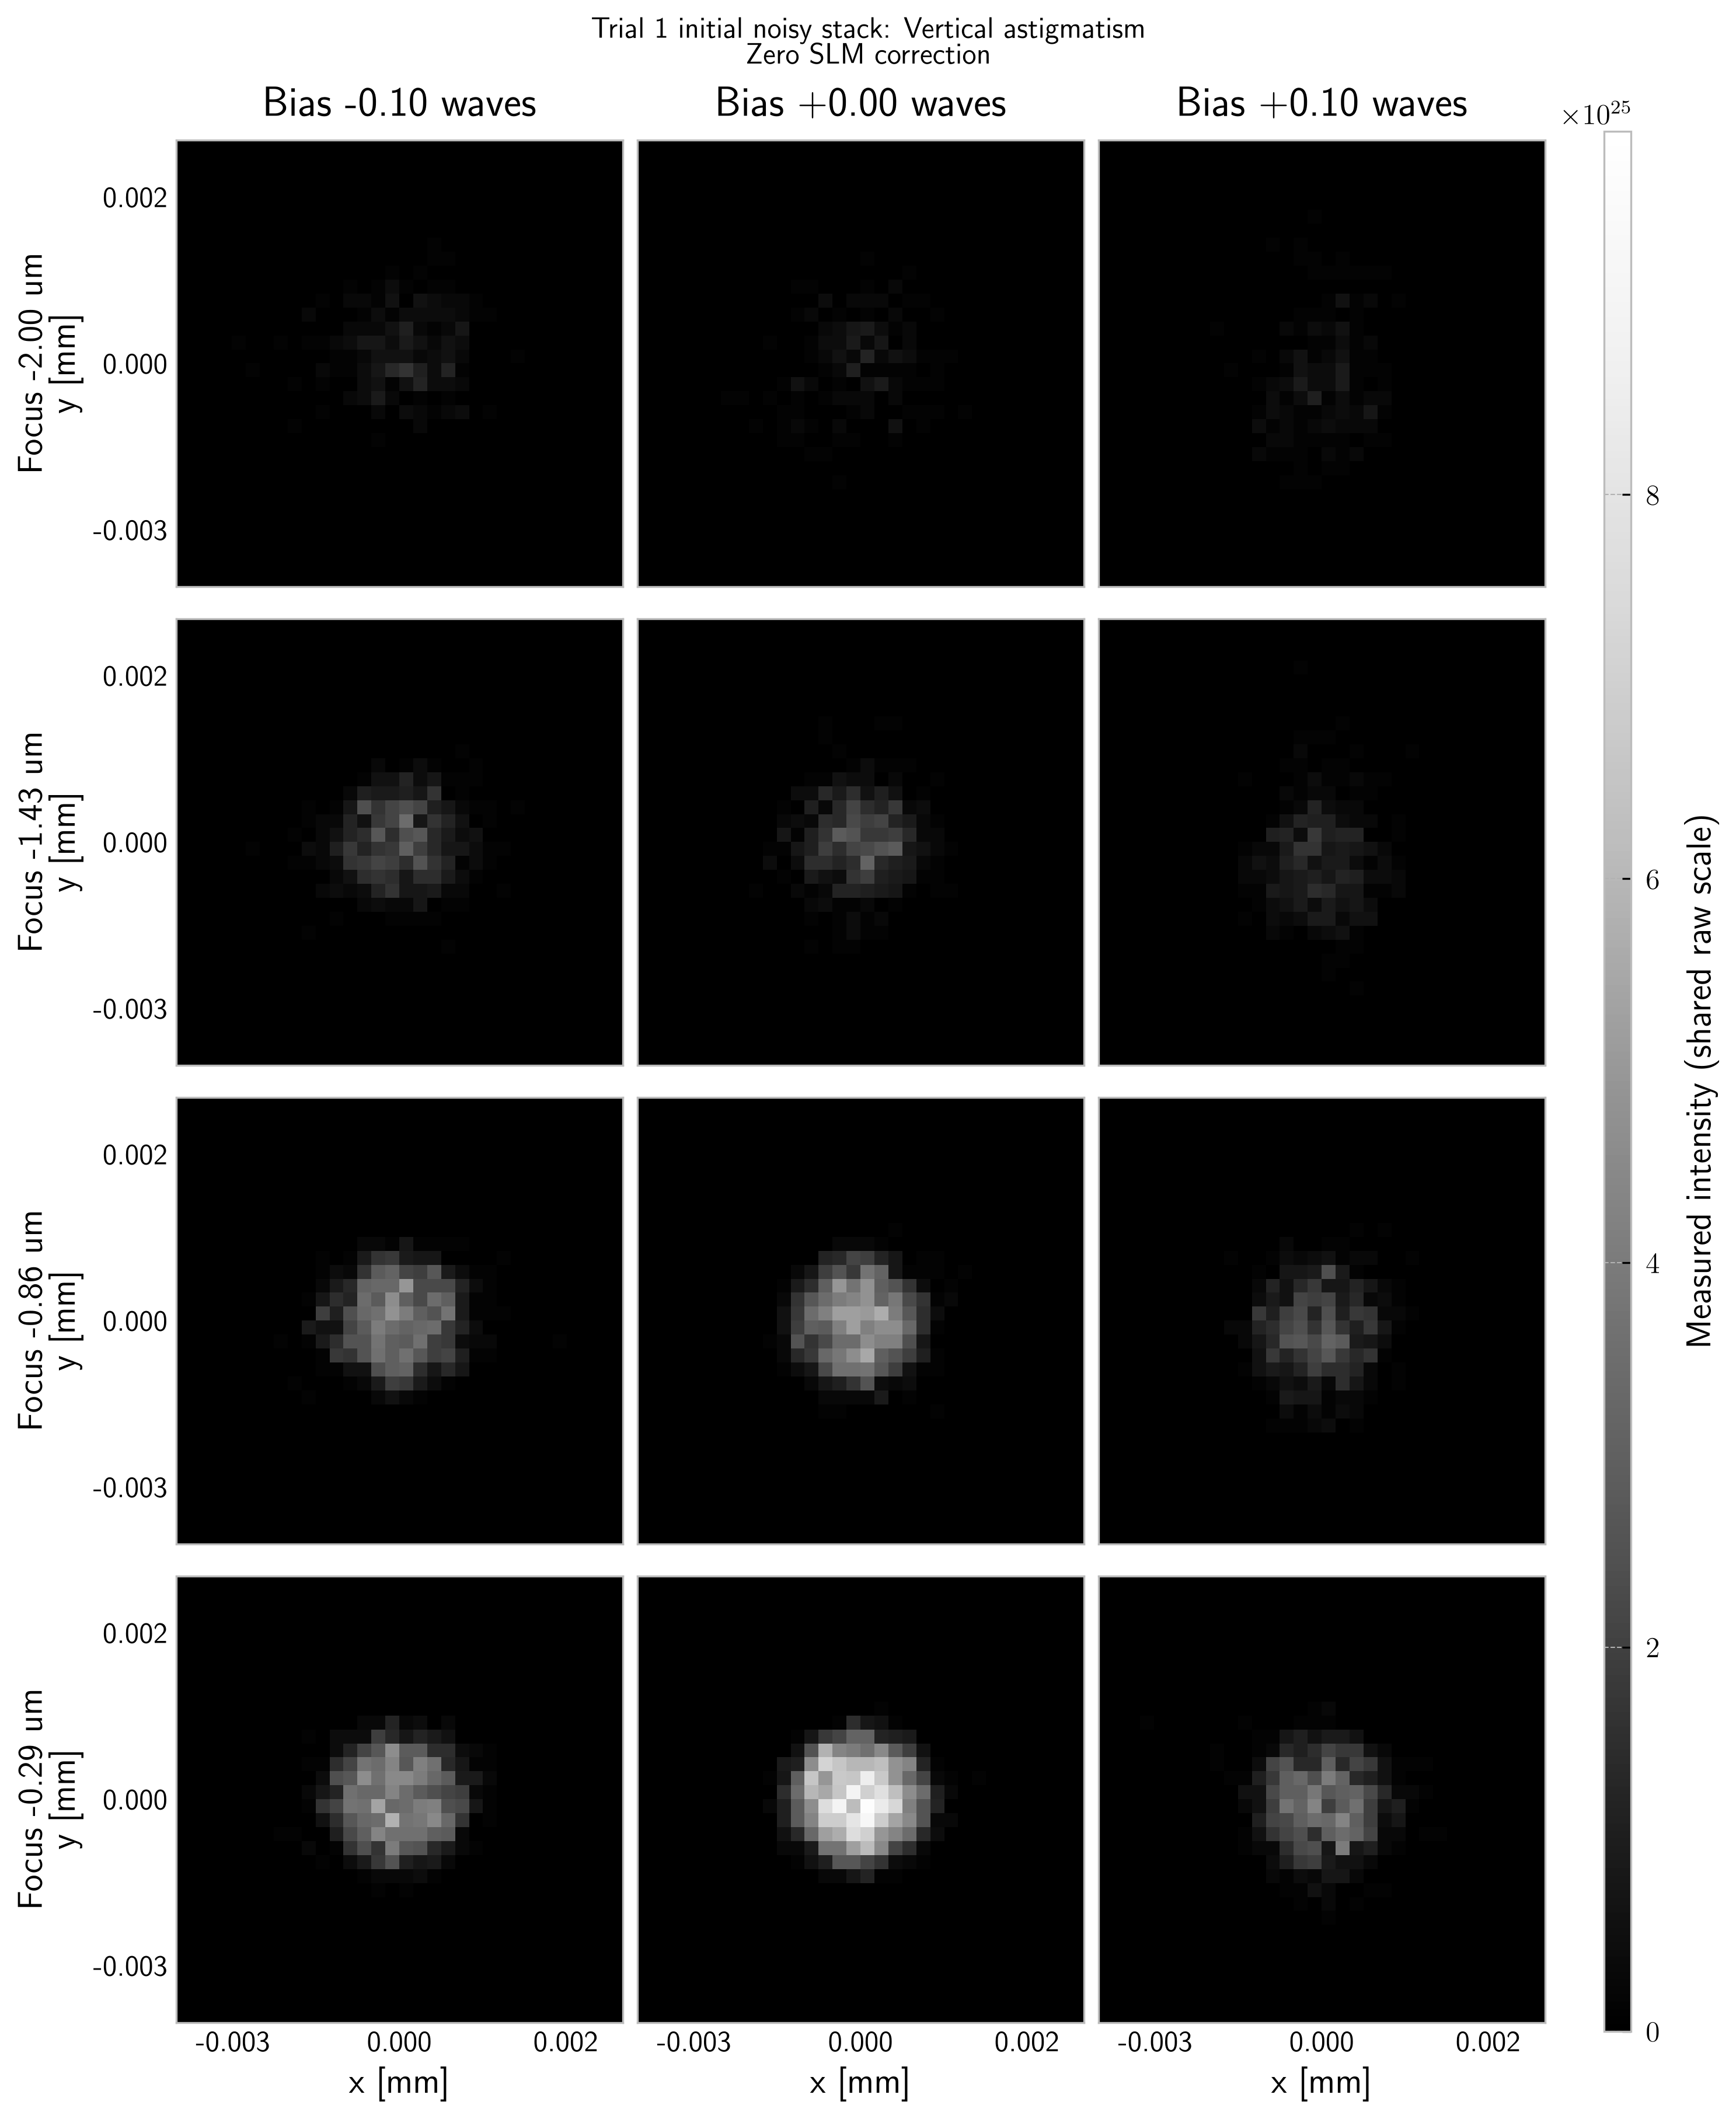

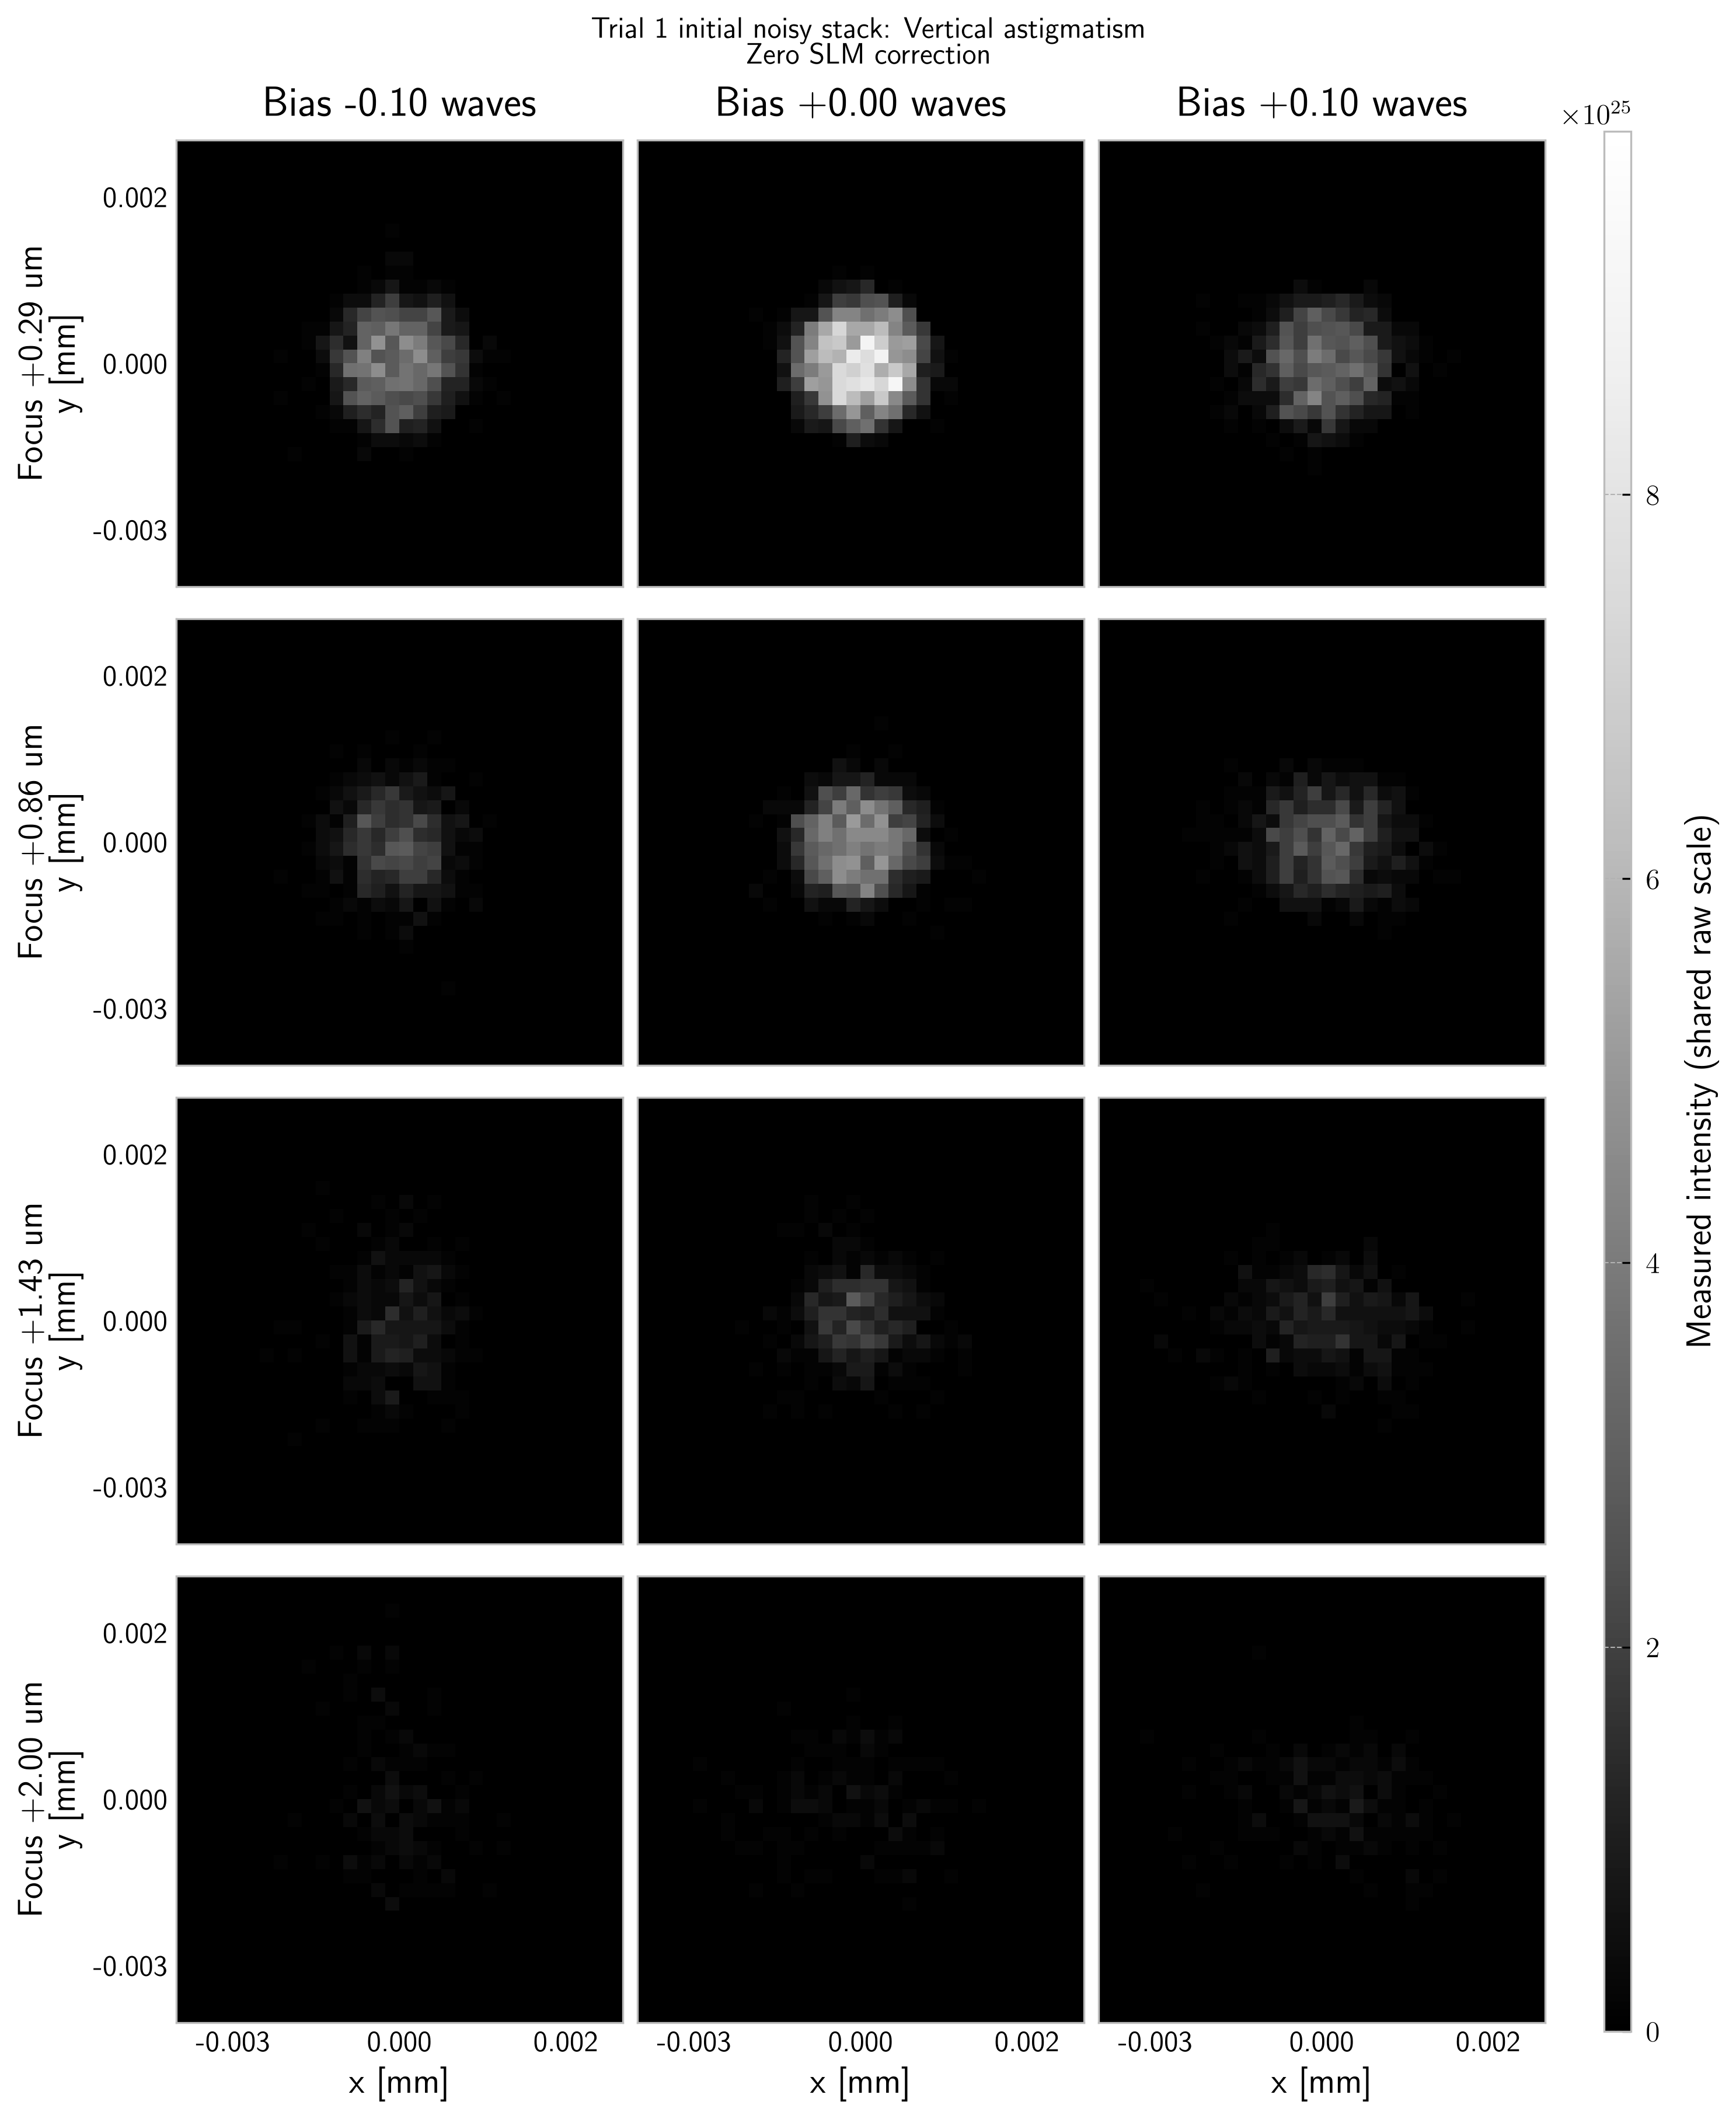

In [179]:
# Separate mode panels and paginate focal positions; all pages share one raw scale.
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
PREVIEW_FOCAL_PLANES_PER_FIGURE = 4
preview_x, preview_y = grid.get_xy()
preview_cube = preview_initial_stack.reshape(
    len(STACK_FOCAL_POSITIONS), len(STACK_DIVERSITY_MODES),
    len(STACK_DIVERSITY_STRENGTHS), len(preview_x), len(preview_y))
preview_vmax = max(float(preview_initial_stack.max()), np.finfo(float).tiny)
mode_names = {(0, 4): "Spherical", (-2, 2): "Oblique astigmatism", (2, 2): "Vertical astigmatism"}
for mode_index, probe_mode in enumerate(STACK_DIVERSITY_MODES):
    for start in range(0, len(STACK_FOCAL_POSITIONS), PREVIEW_FOCAL_PLANES_PER_FIGURE):
        stop = min(start + PREVIEW_FOCAL_PLANES_PER_FIGURE, len(STACK_FOCAL_POSITIONS))
        nrows, ncols = stop-start, len(STACK_DIVERSITY_STRENGTHS)
        fig = plt.figure(figsize=(3*ncols+0.8, 2.8*nrows+0.8), layout="constrained")
        layout = fig.add_gridspec(nrows, ncols+1, width_ratios=[1]*ncols+[0.06])
        axes = np.array([[fig.add_subplot(layout[row, col]) for col in range(ncols)]
                         for row in range(nrows)])
        plotting.plot_many_intensity(
            axes, preview_x, preview_y,
            preview_cube[start:stop, mode_index].reshape(-1, len(preview_x), len(preview_y)),
            normalize=False, vmax=preview_vmax)
        for row, focus in enumerate(STACK_FOCAL_POSITIONS[start:stop]):
            for col, bias in enumerate(STACK_DIVERSITY_STRENGTHS):
                ax = axes[row, col]
                ax.tick_params(axis="both", labelrotation=0)
                ax.xaxis.set_major_locator(MaxNLocator(3))
                ax.yaxis.set_major_locator(MaxNLocator(3))
                ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
                if row == 0:
                    ax.set_title(f"Bias {bias:+.2f} waves", pad=10)
                ax.set_xlabel("x [mm]" if row == nrows-1 else "")
                ax.tick_params(labelbottom=row == nrows-1, labelleft=col == 0)
                ax.set_ylabel(f"Focus {focus*1000:+.2f} um\ny [mm]" if col == 0 else "")
        mode_name = mode_names.get(tuple(probe_mode), f"Z{tuple(probe_mode)}")
        fig.suptitle(f"Trial 1 initial noisy stack: {mode_name}\nZero SLM correction", fontsize=12)
        cax = fig.add_subplot(layout[:, -1])
        colorbar = fig.colorbar(axes[0, 0].images[0], cax=cax)
        colorbar.set_label("Measured intensity (shared raw scale)", labelpad=10)
        colorbar.ax.tick_params(pad=6)
        plt.show()


In [175]:
from systematic_testing.progress import LiveReadouts


def refresh_readouts(**changes):
    correction_readouts.update(**changes)


current_stack_update = 0
current_stack_biases = STACK_DIVERSITY_STRENGTHS.copy()
current_stack_diversity_mode = [m.copy() for m in STACK_DIVERSITY_MODES]


def report_stage(method, event):
    global current_stack_update, current_stack_biases, current_stack_diversity_mode
    if method == "Stack":
        current_stack_update = event["update"]
        if "diversity_modes" in event:
            current_stack_diversity_mode = [m.copy() for m in event["diversity_modes"]]
        if "diversity_strengths" in event:
            current_stack_biases = event["diversity_strengths"].copy()



def report_iteration(event):
    rms_error = event["aberration_rms_error"]
    progress.write(
        f"Trial {trial + 1}/{NUM_TRIALS} | Stack update {current_stack_update}"
        f" | diversity {current_stack_diversity_mode}"
        f" | biases {np.array2string(current_stack_biases, precision=4)} waves"
        f" | optimization step {event['iteration']} | loss {event['loss']:.6e}"
        f" | aberration RMS error {rms_error:.6f} waves"
    )
    refresh_readouts(
        run=f"Trial {trial + 1}/{NUM_TRIALS} | Stack update {current_stack_update}",
        optimizer=(
        f"{event['backend']} | iteration {event['iteration']}/{OPTIMIZER_OPTIONS.get('max_iterations', 50)}"
        f" | loss {event['loss']:.5e} | aberration RMS error {rms_error:.6f} waves"
        f" | scaled gradient max {event['scaled_gradient_inf']:.3e}"
    ))
    if user_iteration_callback is not None:
        user_iteration_callback(event)


def report_update(method, record):
    progress.update(1)
    progress.set_postfix_str(f"trial {trial + 1}/{NUM_TRIALS}, {method}")
    result = (f"{method} | residual RMS {record['residual_rms']:.5f} waves"
              f" | largest modal update {np.max(np.abs(record['update'])):.5f} waves"
              f" | photons {record['photons_detected']:,}")
    changes = dict(result=result, acquisition=f"Images {record['images_taken']}/{IMAGE_BUDGET}")
    if "optimizer_info" in record:
        info = record["optimizer_info"]
        changes["optimizer"] = (f"{info.get('backend', 'unknown backend')} | {info['iterations']} steps"
                                f" | loss {info['loss']:.5e} | success={info['success']} | {info['message']}")
    else:
        changes["optimizer"] = "Booth sweep complete"
    refresh_readouts(**changes)


user_iteration_callback = OPTIMIZER_OPTIONS.get("on_iteration")
readout_optimizer_options = dict(OPTIMIZER_OPTIONS, on_iteration=report_iteration)

correction_truths = []
correction_exposures = []
stack_histories = []
booth_histories = []
correction_total_updates = NUM_TRIALS * (
    IMAGE_BUDGET // stack_images_per_update + IMAGE_BUDGET // booth_images_per_update
)

with tqdm(total=correction_total_updates, desc="Correction comparison", dynamic_ncols=True) as progress, \
        LiveReadouts(progress, interval=None) as correction_readouts:
    refresh_readouts(acquisition=f"Reference SNR {INITIAL_REFERENCE_SNR:g} | fixed exposure {fixed_exposure:.5e}")
    for trial in range(NUM_TRIALS):
        refresh_readouts(run=f"Trial {trial + 1}/{NUM_TRIALS} | preparing correction methods",
                         optimizer="Waiting for acquisition")
        pattern_rng = np.random.default_rng(np.random.SeedSequence([ABERRATION_SEED, trial]))
        truth = zernike.RMSAberration(
            modes=modes, raw_strengths=pattern_rng.normal(0, 1, len(modes)),
            RMS_desired=ABERRATION_RMS, alpha=microscope.alpha,
        )
        correction_truths.append(truth)
        correction_exposures.append(fixed_exposure)

        def make_simulator(method_index):
            return correction.SimulatedSLM(
                microscope=microscope, sample=mask_3D, truth=truth,
                correction_modes=CORRECTION_MODES, exposure=fixed_exposure,
                rng=np.random.default_rng(np.random.SeedSequence([NOISE_SEED, trial, method_index])),
                optical_mode=OPTICAL_MODE,
            )

        stack_histories.append(correction.stack_feedback(
            simulator=make_simulator(0), grid=grid,
            sample_z_levels=z_reconstruction_levels,
            focal_positions=STACK_FOCAL_POSITIONS,
            diversity_mode=STACK_DIVERSITY_MODES[0],
            diversity_modes=STACK_DIVERSITY_MODES,
            diversity_strategy=STACK_DIVERSITY_STRATEGY,
            diversity_strengths=STACK_DIVERSITY_STRENGTHS,
            diversity_decay=STACK_DIVERSITY_DECAY,
            min_diversity_strength=STACK_MIN_DIVERSITY_STRENGTH,
            rho=RHO, image_budget=IMAGE_BUDGET,
            gain=CORRECTION_GAIN, max_update=MAX_MODAL_UPDATE,
            optimizer_kwargs=readout_optimizer_options,
            on_progress=lambda event: report_stage("Stack", event),
            on_update=lambda record: report_update("Stack", record),
        ))
        booth_histories.append(correction.booth_feedback(
            simulator=make_simulator(1), focal_positions=BOOTH_FOCAL_POSITIONS,
            bias=BOOTH_BIAS, image_budget=IMAGE_BUDGET,
            gain=CORRECTION_GAIN, max_update=MAX_MODAL_UPDATE,
            metric=BOOTH_METRIC,
            on_update=lambda record: report_update("Booth", record),
        ))

    refresh_readouts(run=f"Completed {NUM_TRIALS}/{NUM_TRIALS} trials")

# Keep the previous committed correction between complete acquisitions/sweeps.
correction_image_grid = np.arange(IMAGE_BUDGET + 1)
stack_rms_by_images = np.array([
    correction.rms_at_image_counts(history, correction_image_grid)
    for history in stack_histories
])
booth_rms_by_images = np.array([
    correction.rms_at_image_counts(history, correction_image_grid)
    for history in booth_histories
])


Correction comparison:   0%|          | 0/7 [00:00<?, ?it/s]

Run: Preparing | Acquisition: Waiting | Optimizer: Waiting | Latest correction: No completed updates yet | Elapsed: 0.0 s | Current stage: 0.0 s
Run: Trial 1/1 | preparing correction methods | Acquisition: Reference SNR 50 | fixed exposure 1.66815e-23 | Optimizer: Waiting for acquisition | Latest correction: No completed updates yet | Elapsed: 0.0 s | Current stage: 0.0 s


Correction comparison:   0%|          | 0/7 [00:13<?, ?it/s]

Trial 1/1 | Stack update 1 | diversity [[0, 4], [-2, 2], [2, 2]] | biases [-0.1  0.   0.1] waves | optimization step 0 | loss 2.422166e+56 | aberration RMS error 0.100000 waves
Run: Trial 1/1 | Stack update 1 | Acquisition: Reference SNR 50 | fixed exposure 1.66815e-23 | Optimizer: cpu | iteration 0/20 | loss 2.42217e+56 | aberration RMS error 0.100000 waves | scaled gradient max 3.930e+01 | Latest correction: No completed updates yet | Elapsed: 13.6 s | Current stage: 0.0 s


Correction comparison:   0%|          | 0/7 [00:27<?, ?it/s]

...

Correction comparison:   0%|          | 0/7 [03:40<?, ?it/s]

Trial 1/1 | Stack update 1 | diversity [[0, 4], [-2, 2], [2, 2]] | biases [-0.1  0.   0.1] waves | optimization step 17 | loss 1.950200e+55 | aberration RMS error 0.003835 waves


Correction comparison:   0%|          | 0/7 [03:46<?, ?it/s]

Run: Interrupted | Acquisition: Reference SNR 50 | fixed exposure 1.66815e-23 | Optimizer: cpu | iteration 17/20 | loss 1.95020e+55 | aberration RMS error 0.003835 waves | scaled gradient max 1.485e-02 | Latest correction: No completed updates yet | Elapsed: 226.6 s | Current stage: 6.5 s


KeyboardInterrupt: 

In [ ]:
fig, ax = plt.subplots(layout="constrained")
for label, rms_values in [
    ("Stack feedback", stack_rms_by_images),
    (r"Booth $2N+1$", booth_rms_by_images),
]:
    mean_rms = rms_values.mean(axis=0)
    std_rms = rms_values.std(axis=0)
    line, = ax.step(correction_image_grid, mean_rms, where="post", label=label)
    ax.fill_between(
        correction_image_grid, np.maximum(0, mean_rms - std_rms), mean_rms + std_rms,
        step="post", color=line.get_color(), alpha=0.2,
    )
ax.set_xlabel("Images taken")
ax.set_ylabel("Residual wavefront RMS [waves]")
ax.set_xlim(0, IMAGE_BUDGET)
ax.set_ylim(bottom=0)
ax.legend()
fig.savefig(FIGURES_DIR / "correction_rms_vs_images.png", bbox_inches="tight")
plt.show()


In [ ]:
# Numeric results reload without pickled objects; detailed histories remain in memory.
np.savez_compressed(
    RESULTS_DIR / "correction_results.npz",
    images_taken=correction_image_grid,
    stack_rms=stack_rms_by_images,
    booth_rms=booth_rms_by_images,
    truth_modes=np.asarray(modes),
    correction_modes=np.asarray(CORRECTION_MODES),
    truth_strengths=np.array([truth.strengths for truth in correction_truths]),
    exposures=np.asarray(correction_exposures),
    stack_update_images=np.array([[p["images_taken"] for p in h] for h in stack_histories]),
    booth_update_images=np.array([[p["images_taken"] for p in h] for h in booth_histories]),
    stack_slm_strengths=np.array([[p["slm_strengths"] for p in h] for h in stack_histories]),
    booth_slm_strengths=np.array([[p["slm_strengths"] for p in h] for h in booth_histories]),
    stack_detected_photons=np.array([[p["photons_detected"] for p in h] for h in stack_histories]),
    booth_detected_photons=np.array([[p["photons_detected"] for p in h] for h in booth_histories]),
    num_random_starts=OPTIMIZER_OPTIONS["num_random_starts"],
    random_start_rms_range=OPTIMIZER_OPTIONS["random_start_rms_range"],
    random_start_seed=OPTIMIZER_OPTIONS["random_start_seed"],
    rho=RHO, initial_reference_snr=INITIAL_REFERENCE_SNR,
    aberration_rms=ABERRATION_RMS, image_budget=IMAGE_BUDGET,
    stack_focal_positions=STACK_FOCAL_POSITIONS,
    stack_diversity_mode=STACK_DIVERSITY_MODES[0],
            diversity_modes=STACK_DIVERSITY_MODES,
            diversity_strategy=STACK_DIVERSITY_STRATEGY,
    stack_diversity_strengths=STACK_DIVERSITY_STRENGTHS,
    booth_focal_positions=BOOTH_FOCAL_POSITIONS, booth_bias=BOOTH_BIAS,
    correction_gain=CORRECTION_GAIN, max_modal_update=MAX_MODAL_UPDATE,
)
